<a href="https://colab.research.google.com/github/aili01sky/CHE1147H-Group-Project/blob/main/01_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**EXPLORATORY DATA ANALYSIS**

**STRUCTURE AND MISSING DATA**
We first loaded the dataset into Python to examine its dimensions and identify any missing values. This initial step helped us understand the dataset's structure and determine whether data cleaning was needed before proceeding with the analysis.

In [23]:
import pandas as pd

df=pd.read_csv('Dataset_Fixed.csv')
print(df.head())
print(df.shape)

   Unnamed: 0  Average Outflow  Average Inflow  Energy Consumption  Ammonia  \
0           0            2.941           2.589            175856.0     27.0   
1           1            2.936           2.961            181624.0     25.0   
2           2            2.928           3.225            202016.0     42.0   
3           3            2.928           3.354            207547.0     36.0   
4           4            2.917           3.794            202824.0     46.0   

   Biological Oxygen Demand  Chemical Oxygen Demand  Total Nitrogen  \
0                     365.0                   730.0          60.378   
1                     370.0                   740.0          60.026   
2                     418.0                   836.0          64.522   
3                     430.0                   850.0          63.000   
4                     508.0                  1016.0          65.590   

   Average Temperature  Maximum temperature  Minimum temperature  \
0                 19.3        

The dataset contains an extra column (Unnamed: 0) with row numbers only, so it was removed.

In [24]:
#Deleting the columns that are not needed for the analysis
df = df.drop(columns=['Unnamed: 0'])
print(df.head())
print(df.shape)
print(df.columns.tolist())
print(df.info())

   Average Outflow  Average Inflow  Energy Consumption  Ammonia  \
0            2.941           2.589            175856.0     27.0   
1            2.936           2.961            181624.0     25.0   
2            2.928           3.225            202016.0     42.0   
3            2.928           3.354            207547.0     36.0   
4            2.917           3.794            202824.0     46.0   

   Biological Oxygen Demand  Chemical Oxygen Demand  Total Nitrogen  \
0                     365.0                   730.0          60.378   
1                     370.0                   740.0          60.026   
2                     418.0                   836.0          64.522   
3                     430.0                   850.0          63.000   
4                     508.0                  1016.0          65.590   

   Average Temperature  Maximum temperature  Minimum temperature  \
0                 19.3                 25.1                 12.6   
1                 17.1            

Since Python handles date-related calculations more effectively with standardized datetime values, we combined the separate day, month and year columns into a single date column.

In [25]:
#Combine them into one column called 'Date' and convert it to datetime format
date_parts = df[["Year", "Month", "Day"]].rename(
    columns={"Year": "year", "Month": "month", "Day": "day"}
).astype(int)
df['Date'] = pd.to_datetime(date_parts)

print(df[['Year', 'Month', 'Day', 'Date']].head())
print("Start date:", df['Date'].min())
print("End date:", df['Date'].max())

     Year  Month  Day       Date
0  2014.0    1.0  1.0 2014-01-01
1  2014.0    1.0  2.0 2014-01-02
2  2014.0    1.0  5.0 2014-01-05
3  2014.0    1.0  6.0 2014-01-06
4  2014.0    1.0  7.0 2014-01-07
Start date: 2014-01-01 00:00:00
End date: 2019-06-27 00:00:00


To check for gaps in the date coverage, we compared the number of observations with the number of calendar days in the dataset's date range. The dataset contains 1,382 observations across a 2,004-day period, so it does not include a record for every day. This indicates gaps in daily coverage.

In [26]:
#Sorting Date
df = df.sort_values(by='Date').reset_index(drop=True)

#Checking for missing values
gaps = df['Date'].diff().dt.days
print(gaps.value_counts().head())

#Checking whether the dataset has any missing values
expected_days = (df['Date'].max() - df['Date'].min()).days + 1
actual_days = df['Date'].nunique()
print(f"Expected days: {expected_days}, Actual days: {actual_days}")


Date
1.0     1066
3.0      267
2.0       43
4.0        2
20.0       1
Name: count, dtype: int64
Expected days: 2004, Actual days: 1382


In [27]:
#Find the data which is 0
zero_share = ((df == 0).mean() * 100).round(1).sort_values(ascending=False)
print(zero_share)

Atmospheric pressure        99.6
Total rainfall              92.1
Average visibility          20.0
Maximum temperature          0.7
Minimum temperature          0.6
Average wind speed           0.4
Average humidity             0.4
Average Temperature          0.4
Maximum wind speed           0.4
Energy Consumption           0.0
Average Inflow               0.0
Average Outflow              0.0
Ammonia                      0.0
Chemical Oxygen Demand       0.0
Total Nitrogen               0.0
Biological Oxygen Demand     0.0
Year                         0.0
Month                        0.0
Day                          0.0
Date                         0.0
dtype: float64


**HANDLING ZERO VALUE**

Atmospheric pressure was recorded as 0 in 99.6% of observations. Because zero is not a plausible atmospheric pressure reading and the value is nearly constant, we removed this column from the analysis. For the other variables where zero is not a plausible measurement (average visibility, temperature, and humidity), we treated zero values as missing and replaced them with `NaN`.

In [28]:
import numpy as np

#Based on the data, eliminate the columns which is impossible to have 0 values
df = df.drop(columns=["Atmospheric pressure"])

#Columns with 0 values are likely to be missing data, so we will replace them with NaN
zero_is_missing = ["Average visibility","Maximum temperature","Average Temperature","Average humidity"]
df[zero_is_missing] = df[zero_is_missing].replace(0, np.nan)

#Checking the number of missing values in each column
print(df[zero_is_missing].isna().sum())

#Row with at least one missing value
print("Row affected by missing values:", df[zero_is_missing].isna().any(axis=1).sum())

Average visibility     277
Maximum temperature     10
Average Temperature      5
Average humidity         5
dtype: int64
Row affected by missing values: 282


**SUMMARY STATISTICS**

The table below summarizes the numerical variables in the dataset. It reports the number of non-missing observations (`count`), the mean and standard deviation, the minimum and maximum, and the 25th, 50th (median), and 75th percentiles. The `skew` column describes the asymmetry of each variable's distribution: values near zero indicate a more symmetric distribution, while positive or negative values indicate a longer tail to the right or left, respectively. Counts may differ across variables because missing values are excluded from these calculations.

In [29]:
# Columns to analyze (without Day, Month, Year, Date)
cols = ["Average Inflow", "Average Outflow", "Energy Consumption", "Ammonia",
        "Biological Oxygen Demand", "Chemical Oxygen Demand", "Total Nitrogen",
        "Average Temperature", "Maximum temperature", "Minimum temperature",
        "Average humidity", "Total rainfall", "Average visibility",
        "Average wind speed", "Maximum wind speed"]

# describe() returns a summary of statistics for each column, including count, mean, std, min, 25%, 50%, 75%, and max
summary = df[cols].describe().T

# Skewness: 0 = symmetric, positive = long tail to the right
summary["skew"] = df[cols].skew()

print(summary.round(2))

                           count       mean       std        min        25%  \
Average Inflow            1382.0       4.51      1.44       2.59       3.64   
Average Outflow           1382.0       3.93      1.23       0.00       3.07   
Energy Consumption        1382.0  275159.09  44640.53  116638.00  246435.75   
Ammonia                   1382.0      39.22      7.76      13.00      34.00   
Biological Oxygen Demand  1382.0     382.06     86.00     140.00     330.00   
Chemical Oxygen Demand    1382.0     845.96    145.42     360.00     751.25   
Total Nitrogen            1382.0      62.74      3.57      40.00      61.40   
Average Temperature       1377.0      15.09      5.33       4.70      10.80   
Maximum temperature       1372.0      20.68      6.90       8.10      15.00   
Minimum temperature       1382.0      10.04      4.66      -2.00       6.80   
Average humidity          1377.0      63.79     14.05      16.00      56.00   
Total rainfall            1382.0       0.22      1.3

**INVESTIGATING UNUSUAL VALUES**

We inspected unusually high visibility and total nitrogen readings, as well as near-zero outflow measurements. Two visibility values exceeded 100 km, which is implausible. There were 24 days with near-zero outflow even though energy consumption remained similar to that on other days, suggesting that these readings may reflect a measurement issue rather than normal operation. Total nitrogen also showed two isolated spikes (86 and 92 mg/L), while nearby readings were around 64 mg/L. Based on these checks, the implausible visibility values, near-zero outflow readings, and isolated nitrogen spikes were treated as missing in the subsequent cleaning step.

In [30]:
# Days with an implausible visibility value
print(df.loc[df["Average visibility"] > 100, ["Date", "Average visibility"]])

# Days with (almost) zero outflow
print(df.loc[df["Average Outflow"] < 0.1, ["Date", "Average Outflow"]])

# Days with extremely high total nitrogen
print(df.loc[df["Total Nitrogen"] > 80, ["Date", "Total Nitrogen"]])

          Date  Average visibility
126 2014-06-29               512.0
897 2017-07-16               101.0
           Date  Average Outflow
1064 2018-03-08         0.028000
1295 2019-02-21         0.000004
1296 2019-02-24         0.000004
1297 2019-02-25         0.000004
1298 2019-02-26         0.000004
1299 2019-02-27         0.000004
1300 2019-02-28         0.000004
1307 2019-03-11         0.000004
1308 2019-03-12         0.000004
1309 2019-03-13         0.000004
1310 2019-03-14         0.000004
1311 2019-03-17         0.000004
1312 2019-03-18         0.000004
1313 2019-03-19         0.000004
1314 2019-03-20         0.000004
1315 2019-03-21         0.000004
1316 2019-03-24         0.000004
1317 2019-03-25         0.000004
1318 2019-03-26         0.000004
1319 2019-03-27         0.000004
1320 2019-03-28         0.000004
1321 2019-03-31         0.000004
1341 2019-05-01         0.000004
1342 2019-05-02         0.002000
          Date  Total Nitrogen
440 2015-09-30            86.0
469 2015

In [31]:
import numpy as np

# 1. Visibility above 100 km is impossible: set those 2 values to missing
df.loc[df["Average visibility"] > 100, "Average visibility"] = np.nan

# 2. Near-zero outflow: how many rows, and over what dates?
low_out = df["Average Outflow"] < 0.1
print("Rows with near-zero outflow:", low_out.sum())
print("From", df.loc[low_out, "Date"].min(), "to", df.loc[low_out, "Date"].max())

# Was the plant running on those days? Compare average energy use
print("Mean energy, near-zero outflow days:", round(df.loc[low_out, "Energy Consumption"].mean()))
print("Mean energy, all other days:", round(df.loc[~low_out, "Energy Consumption"].mean()))

# 3. Look at the 3 days before and after each high nitrogen value
for i in [440, 469]:
    print(df.loc[i-3:i+3, ["Date", "Total Nitrogen"]])


Rows with near-zero outflow: 24
From 2018-03-08 00:00:00 to 2019-05-02 00:00:00
Mean energy, near-zero outflow days: 266406
Mean energy, all other days: 275314
          Date  Total Nitrogen
437 2015-09-27          63.097
438 2015-09-28          64.120
439 2015-09-29          63.774
440 2015-09-30          86.000
441 2015-10-02          63.931
442 2015-10-04          64.953
443 2015-10-05          64.849
          Date  Total Nitrogen
466 2015-11-08          61.591
467 2015-11-09          64.321
468 2015-11-10          68.183
469 2015-11-11          92.000
470 2015-11-12          64.477
471 2015-11-15          63.136
472 2015-11-16          61.942


In [32]:
import numpy as np

# Near-zero outflow (< 0.1 m3/s) while the plant was running: sensor failure -> missing
df.loc[df["Average Outflow"] < 0.1, "Average Outflow"] = np.nan

# Isolated one-day nitrogen spikes (> 80 mg/L, neighbors are about 64) -> missing
df.loc[df["Total Nitrogen"] > 80, "Total Nitrogen"] = np.nan

# Check the total number of missing values per column now
print(df.isna().sum()[df.isna().sum() > 0])

Average Outflow         24
Total Nitrogen           2
Average Temperature      5
Maximum temperature     10
Average humidity         5
Average visibility     279
dtype: int64


**DISTRIBUTION OF NUMERICAL VARIABLES**

Histograms help us see how frequently different values occur and whether a variable is symmetric or skewed. Daily energy consumption is relatively symmetric, with its mean and median close together. Other variables have more uneven distributions: inflow and rainfall are right-skewed, and rainfall has many zero-value days. The plots also make it easier to compare the spread and shape of the selected measurements.

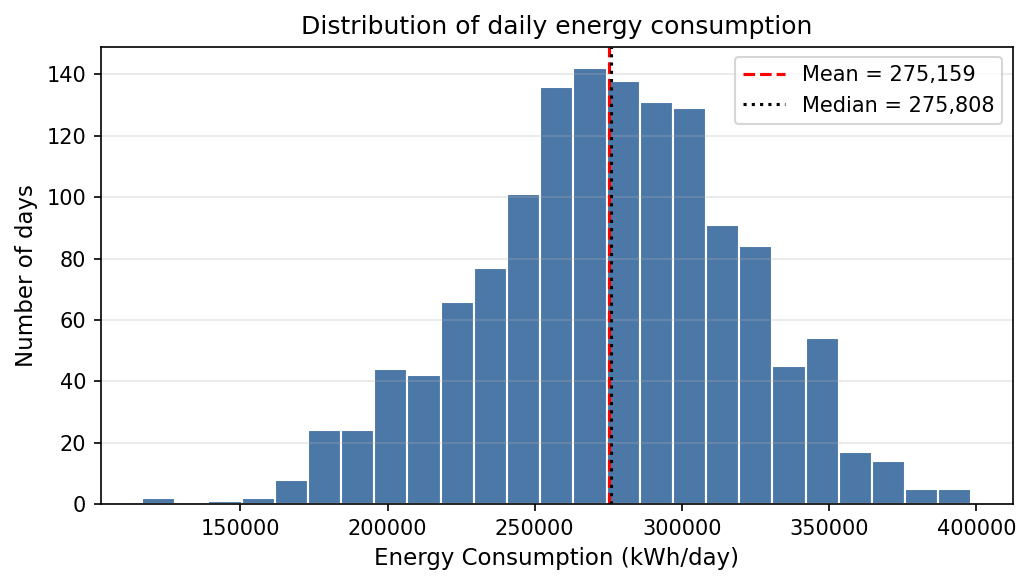

In [33]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4), dpi=150)   # dpi = sharper image for the report

# edgecolor draws a thin line around each bar so they are easier to tell apart
ax.hist(df["Energy Consumption"], bins=25, color="#4C78A8", edgecolor="white")

# Vertical lines for the mean and the median
mean_val = df["Energy Consumption"].mean()
median_val = df["Energy Consumption"].median()
ax.axvline(mean_val, color="red", linestyle="--", linewidth=1.5, label=f"Mean = {mean_val:,.0f}")
ax.axvline(median_val, color="black", linestyle=":", linewidth=1.5, label=f"Median = {median_val:,.0f}")

ax.set_xlabel("Energy Consumption (kWh/day)", fontsize=11)
ax.set_ylabel("Number of days", fontsize=11)
ax.set_title("Distribution of daily energy consumption", fontsize=12)
ax.grid(axis="y", alpha=0.3)          # light horizontal grid lines
ax.legend()                           # shows the labels for the two lines

plt.tight_layout()
plt.show()

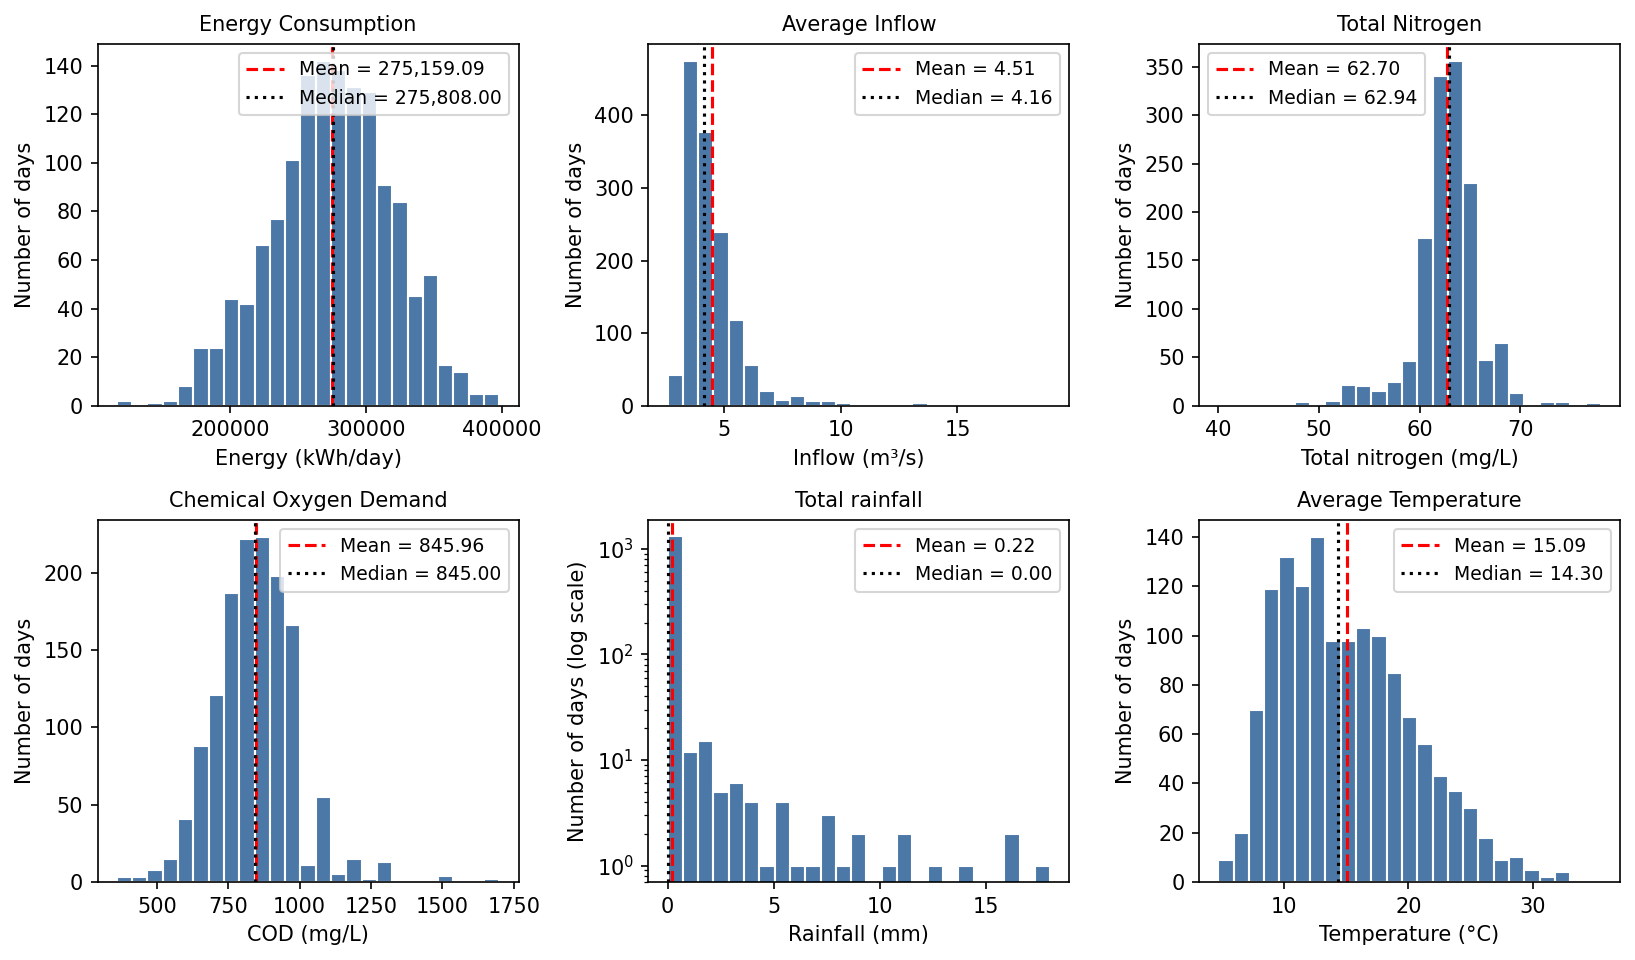

In [34]:
import matplotlib.pyplot as plt

# Variables to show, with the x-axis label (including units) for each
plots = {
    "Energy Consumption": "Energy (kWh/day)",
    "Average Inflow": "Inflow (m³/s)",
    "Total Nitrogen": "Total nitrogen (mg/L)",
    "Chemical Oxygen Demand": "COD (mg/L)",
    "Total rainfall": "Rainfall (mm)",
    "Average Temperature": "Temperature (°C)",
}

fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), dpi=150)   # 2 rows x 3 columns of small plots

for ax, (col, label) in zip(axes.ravel(), plots.items()):
    data = df[col].dropna()                  # ignore missing values

    ax.hist(data, bins=25, color="#4C78A8", edgecolor="white")

    # Mean (red dashed) and median (black dotted) of this variable
    ax.axvline(data.mean(), color="red", linestyle="--", linewidth=1.5, label=f"Mean = {data.mean():,.2f}")
    ax.axvline(data.median(), color="black", linestyle=":", linewidth=1.5, label=f"Median = {data.median():,.2f}")

    ax.set_xlabel(label)
    ax.set_ylabel("Number of days")
    ax.set_title(col, fontsize=10)
    ax.legend(fontsize=9)                    # small legend in each panel with the exact values

    # Rainfall: a log y-axis makes the few rainy days visible next to the huge bar at 0
    if col == "Total rainfall":
        ax.set_yscale("log")
        ax.set_ylabel("Number of days (log scale)")

plt.tight_layout()
plt.show()

In [35]:
#Check whether it has a correlation between inflow and rainfall
# Correlation between inflow and rainfall
print(df[["Average Inflow", "Total rainfall"]].corr())

# The 10 days with the highest inflow, next to that day's rainfall
print(df.nlargest(10, "Average Inflow")[["Date", "Average Inflow", "Total rainfall"]])

                Average Inflow  Total rainfall
Average Inflow        1.000000       -0.100358
Total rainfall       -0.100358        1.000000
           Date  Average Inflow  Total rainfall
766  2017-01-05          18.968             0.0
1268 2019-01-14          17.360             0.0
1060 2018-03-04          14.551             0.0
669  2016-08-23          14.488             0.0
668  2016-08-22          13.713             0.0
744  2016-12-06          13.368             0.0
765  2017-01-04          13.246             0.0
767  2017-01-08          13.169             0.0
832  2017-04-11          12.893             0.0
1061 2018-03-05          12.652             0.0


In [36]:
#There's no correlation between inflow and rainfall, as the correlation coefficient is very low (-0.10). This means that the inflow is not significantly affected by the amount of rainfall on that day.
# The 10 highest-inflow days, with outflow and energy for the same days
top = df.nlargest(10, "Average Inflow")[["Date", "Average Inflow", "Average Outflow", "Energy Consumption"]]
print(top)

# For comparison: the average outflow and energy over all days
print("Mean outflow, all days:", round(df["Average Outflow"].mean(), 2))
print("Mean energy, all days:", round(df["Energy Consumption"].mean()))

           Date  Average Inflow  Average Outflow  Energy Consumption
766  2017-01-05          18.968            7.904            289960.0
1268 2019-01-14          17.360            7.635            248053.0
1060 2018-03-04          14.551            6.032            318847.0
669  2016-08-23          14.488            7.211            292775.0
668  2016-08-22          13.713            5.902            310318.0
744  2016-12-06          13.368            7.274            318615.0
765  2017-01-04          13.246            6.518            315502.0
767  2017-01-08          13.169            7.920            234544.0
832  2017-04-11          12.893            5.189            321321.0
1061 2018-03-05          12.652            6.625            294423.0
Mean outflow, all days: 4.0
Mean energy, all days: 275159


**OUTLIER SCREENING**

We used boxplots and the 1.5 times the IQR rule to flag values that fall unusually far from the middle 50% of observations. These are potential outliers, not necessarily errors, so they should be interpreted in context rather than removed automatically. The screening flagged 69 Average Inflow values (5.0%), 123 Total Nitrogen values (8.9%), 44 Chemical Oxygen Demand values (3.2%), 58 Biological Oxygen Demand values (4.2%), 11 Ammonia values (0.8%), and 6 Energy Consumption values (0.4%). The flagged observations can reflect genuine variation or data-quality issues and should be investigated before deciding how to handle them.

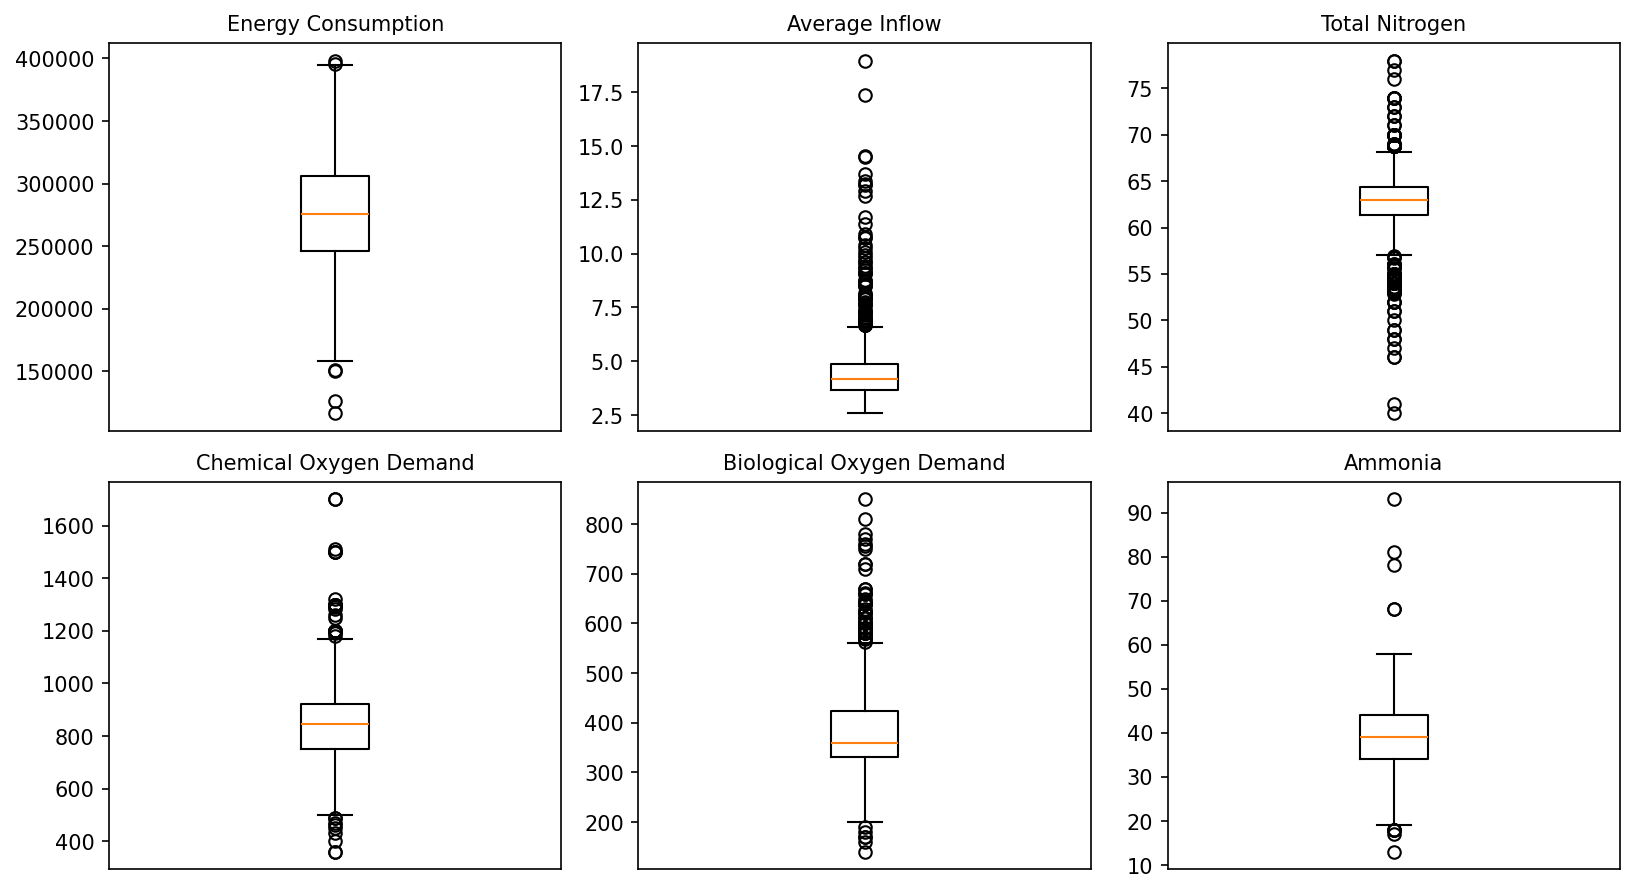

Energy Consumption: 6 outliers (0.4% of days)
Average Inflow: 69 outliers (5.0% of days)
Total Nitrogen: 123 outliers (8.9% of days)
Chemical Oxygen Demand: 44 outliers (3.2% of days)
Biological Oxygen Demand: 58 outliers (4.2% of days)
Ammonia: 11 outliers (0.8% of days)


In [37]:
import matplotlib.pyplot as plt

# Variables to check for outliers
out_cols = ["Energy Consumption", "Average Inflow", "Total Nitrogen",
            "Chemical Oxygen Demand", "Biological Oxygen Demand", "Ammonia"]

fig, axes = plt.subplots(2, 3, figsize=(11, 6), dpi=150)

for ax, c in zip(axes.ravel(), out_cols):
    # Boxplot: the box is the middle 50% of days, the line is the median,
    # dots beyond the whiskers are possible outliers
    ax.boxplot(df[c].dropna())
    ax.set_title(c, fontsize=10)
    ax.set_xticks([])            # no x label needed with only one box

plt.tight_layout()
plt.show()

# Count outliers with the IQR rule: beyond 1.5 x IQR from the quartiles
for c in out_cols:
    data = df[c].dropna()
    q1, q3 = data.quantile(0.25), data.quantile(0.75)
    iqr = q3 - q1                                    # spread of the middle 50%
    n_out = ((data < q1 - 1.5 * iqr) | (data > q3 + 1.5 * iqr)).sum()
    print(f"{c}: {n_out} outliers ({100 * n_out / len(data):.1f}% of days)")

In [38]:
# How many nitrogen values are well below normal, and how low do they go?
print((df["Total Nitrogen"] < 50).sum(), "days below 50 mg/L")
print(df.nsmallest(5, "Total Nitrogen")[["Date", "Total Nitrogen", "Energy Consumption"]])

9 days below 50 mg/L
           Date  Total Nitrogen  Energy Consumption
340  2015-05-13            40.0            361830.0
699  2016-10-04            41.0            380550.0
145  2014-07-24            46.0            339981.0
787  2017-02-06            46.0            283990.0
1013 2017-12-27            47.0            295216.0


**FEATURE RELATIONSHIPS**

We examined the pairwise correlations among the numerical variables and their relationships with energy consumption using a correlation matrix. Correlation values range from -1 to 1: values near either extreme indicate a stronger linear relationship, while values near 0 indicate a weaker one. The strongest correlations with energy consumption are negative and involve the temperature variables (about -0.24 to -0.28); inflow and outflow have weak positive correlations (about 0.18 and 0.19). These results describe linear associations only and do not establish causation.

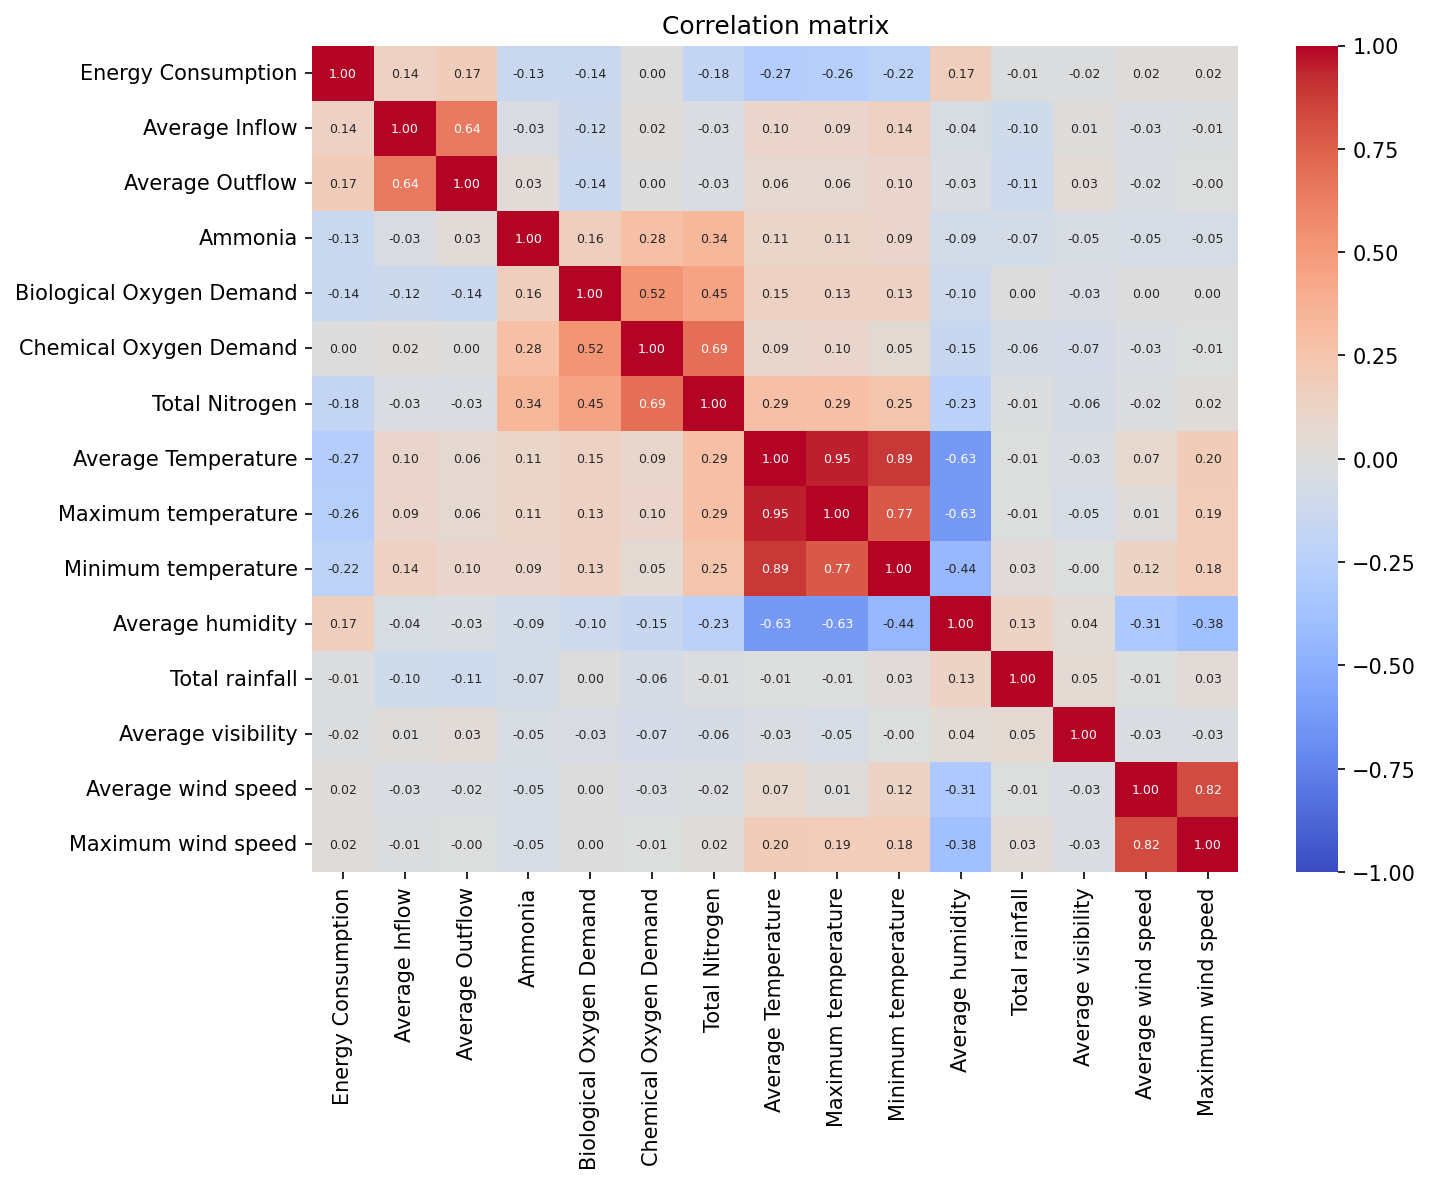

Average Outflow             0.17
Average humidity            0.17
Average Inflow              0.14
Average wind speed          0.02
Maximum wind speed          0.02
Chemical Oxygen Demand      0.00
Total rainfall             -0.01
Average visibility         -0.02
Ammonia                    -0.13
Biological Oxygen Demand   -0.14
Total Nitrogen             -0.18
Minimum temperature        -0.22
Maximum temperature        -0.26
Average Temperature        -0.27
Name: Energy Consumption, dtype: float64


In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

# Columns to compare (no Day, Month, Year, Date)
cols = ["Energy Consumption", "Average Inflow", "Average Outflow", "Ammonia",
        "Biological Oxygen Demand", "Chemical Oxygen Demand", "Total Nitrogen",
        "Average Temperature", "Maximum temperature", "Minimum temperature",
        "Average humidity", "Total rainfall", "Average visibility",
        "Average wind speed", "Maximum wind speed"]

corr = df[cols].corr()                  # correlation of every pair; missing values are skipped

plt.figure(figsize=(10, 8), dpi=150)
# annot=True prints the number in each cell; center=0 makes 0 the neutral color
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 6},
            cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

# Correlation of each variable with the target
print(corr["Energy Consumption"].drop("Energy Consumption").sort_values(ascending=False).round(2))

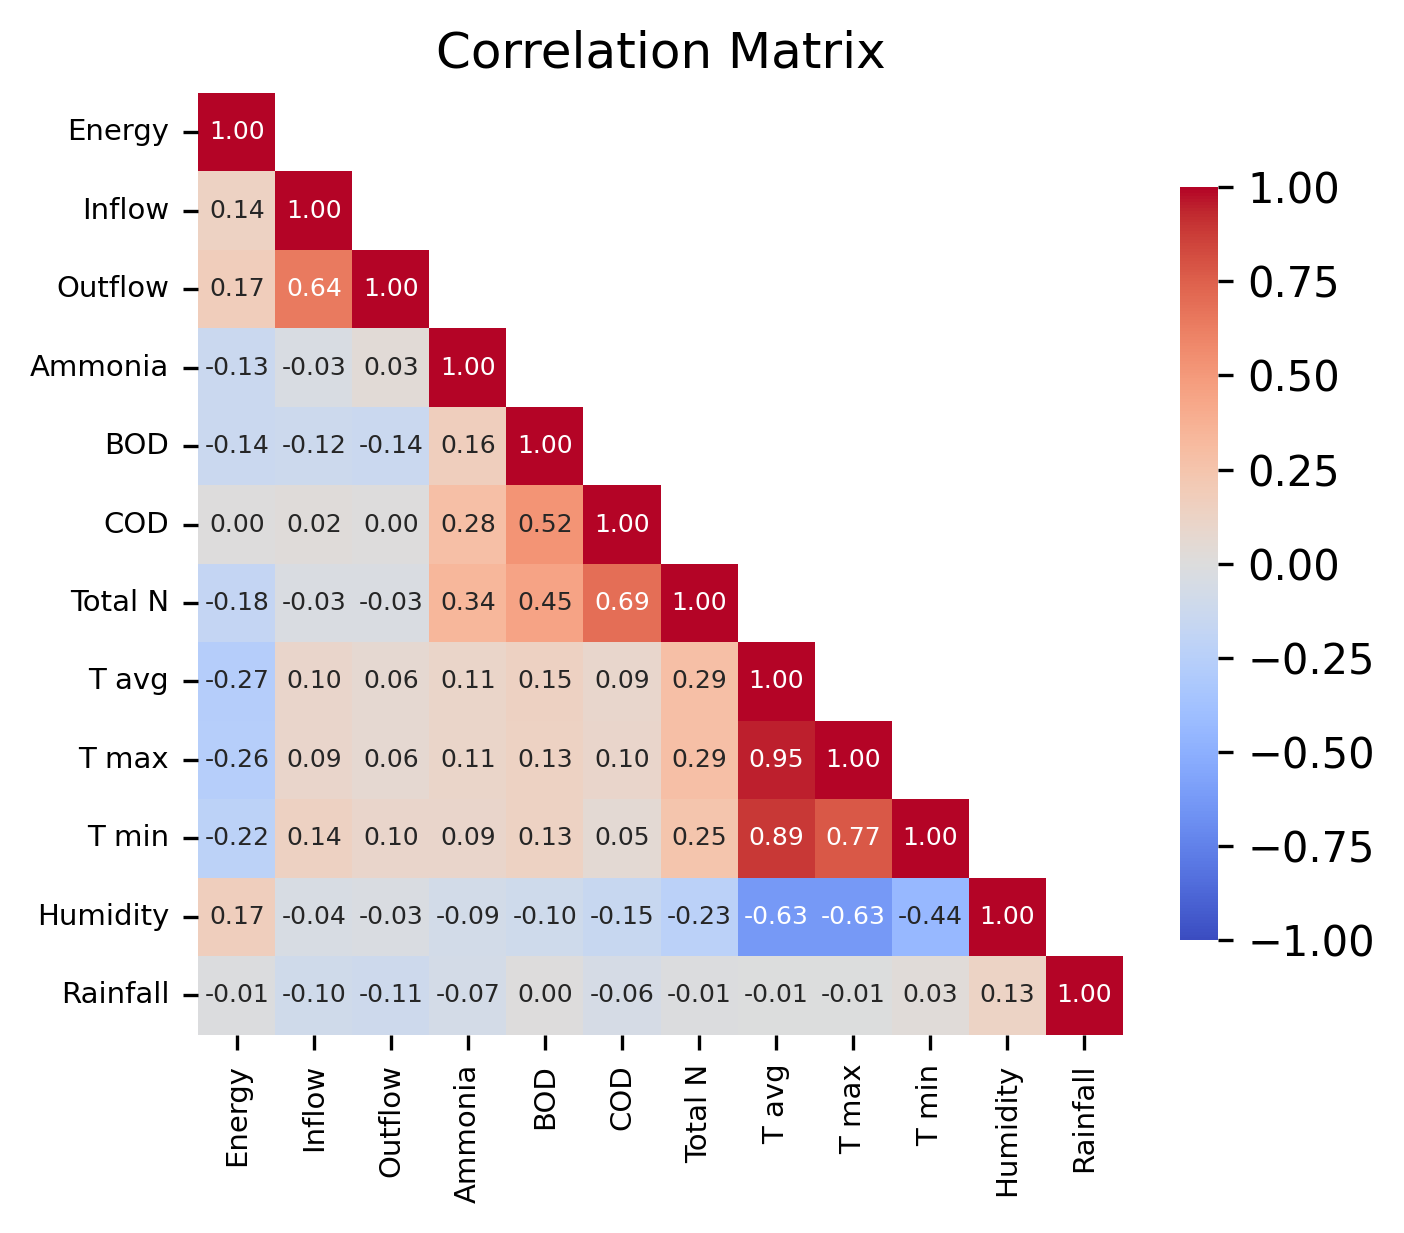

Inflow-Outflow: 0.64
COD-BOD: 0.52 | COD-Total N: 0.69


In [40]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

short = {"Energy Consumption": "Energy", "Average Inflow": "Inflow", "Average Outflow": "Outflow",
         "Ammonia": "Ammonia", "Biological Oxygen Demand": "BOD", "Chemical Oxygen Demand": "COD",
         "Total Nitrogen": "Total N", "Average Temperature": "T avg", "Maximum temperature": "T max",
         "Minimum temperature": "T min", "Average humidity": "Humidity", "Total rainfall": "Rainfall"}

corr = df[list(short)].rename(columns=short).corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)              # hide the repeated upper half

fig, ax = plt.subplots(figsize=(4.8, 4), dpi=300)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 6},
            cmap="coolwarm", center=0, vmin=-1, vmax=1, cbar_kws={"shrink": 0.8}, ax=ax)
ax.tick_params(labelsize=7)
plt.tight_layout()
plt.title("Correlation Matrix")
plt.savefig("fig2_heatmap_small.png", dpi=300, bbox_inches="tight")
plt.show()

# Numbers you need for the text (see point 2 below)
print("Inflow-Outflow:", round(corr.loc["Inflow", "Outflow"], 2))
print("COD-BOD:", round(corr.loc["COD", "BOD"], 2), "| COD-Total N:", round(corr.loc["COD", "Total N"], 2))

The correlation matrix shows that no single variable has a strong linear relationship with energy consumption. The largest correlations are with temperature (negative, approximately -0.24 to -0.28), while inflow, outflow, and humidity have weak positive correlations. The temperature variables are also strongly correlated with one another, so they provide overlapping information. Correlation describes association, not causation.

Average Temperature  Maximum temperature    0.95
                     Minimum temperature    0.89
Maximum temperature  Minimum temperature    0.77
Average wind speed   Maximum wind speed     0.82
dtype: float64
Average Temperature        -0.28
Maximum temperature        -0.28
Minimum temperature        -0.24
Total Nitrogen             -0.19
Ammonia                    -0.14
Biological Oxygen Demand   -0.14
Total rainfall             -0.05
Average visibility         -0.05
Maximum wind speed          0.01
Average wind speed          0.01
Chemical Oxygen Demand      0.01
Average humidity            0.16
Average Inflow              0.18
Average Outflow             0.19
Name: Energy Consumption, dtype: float64


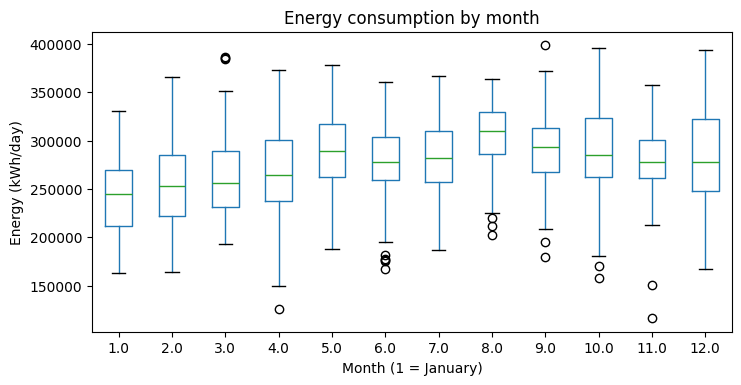

In [41]:
import numpy as np
import matplotlib.pyplot as plt
corr = df[cols].corr()   # recompute the full correlation matrix (the small heat map above uses short names)

# 1. Pairs of features strongly correlated with each other (|r| > 0.7)
feat = corr.drop(index="Energy Consumption", columns="Energy Consumption")
upper = feat.where(np.triu(np.ones(feat.shape, dtype=bool), k=1))   # keep each pair once
pairs = upper.stack()
print(pairs[pairs.abs() > 0.7].round(2))

# 2. Spearman correlation with energy (catches curved but consistently rising or falling links)
print(df[cols].corr(method="spearman")["Energy Consumption"].drop("Energy Consumption").round(2).sort_values())

# 3. Does energy change through the year? One boxplot per month
df.boxplot(column="Energy Consumption", by="Month", figsize=(8, 4), grid=False)
plt.suptitle("")                              # remove the automatic extra title
plt.title("Energy consumption by month")
plt.xlabel("Month (1 = January)")
plt.ylabel("Energy (kWh/day)")
plt.show()

The additional checks support the same conclusion: the Spearman correlations with energy consumption are also weak, so there is no strong monotonic relationship with any one measured variable. The pairwise checks also identify strong correlations among the temperature variables and between average and maximum wind speed. These related predictors may contain overlapping information and should be considered together when selecting features for a predictive model.

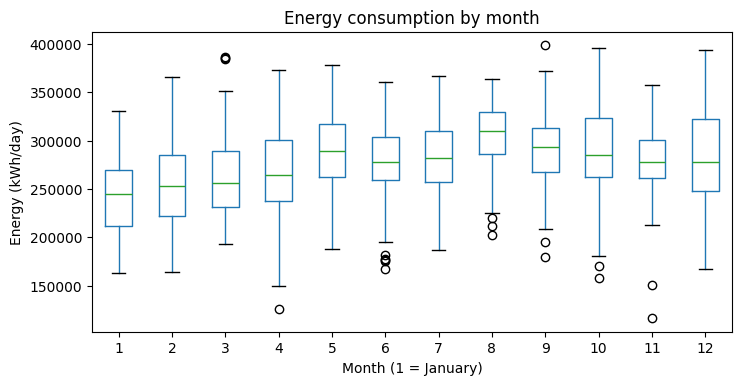

In [42]:
import matplotlib.pyplot as plt

# Month is stored as a float (1.0); astype(int) turns it into 1, 2, ... for clean labels
df["Month"] = df["Month"].astype(int)

df.boxplot(column="Energy Consumption", by="Month", figsize=(8, 4), grid=False)
plt.suptitle("")
plt.title("Energy consumption by month")
plt.xlabel("Month (1 = January)")
plt.ylabel("Energy (kWh/day)")
plt.show()

**ENERGY OVER TIME**

This plot shows daily energy consumption from 2014 to 2019, along with a rolling mean across 30 recorded observations to make the overall trend easier to see. Because some dates are missing, this rolling mean does not always represent exactly 30 calendar days. Average annual consumption increased from about 257,847 kWh/day in 2014 to a peak of 293,217 kWh/day in 2017, then decreased in 2018 and 2019. The 2019 average is based on fewer observations (120) than the earlier years, so it represents only part of the year and should be interpreted with caution.

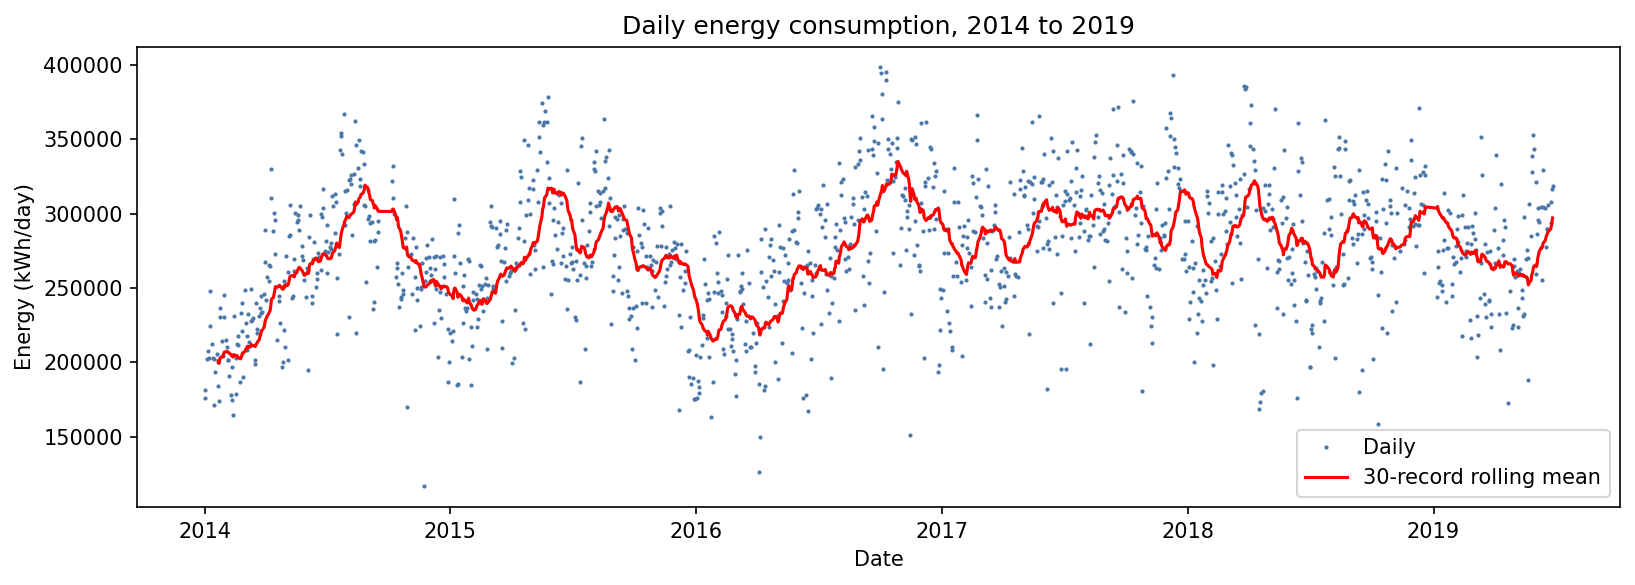

          mean  count
Date                 
2014  257847.0    245
2015  271593.0    258
2016  269871.0    260
2017  293217.0    253
2018  284566.0    246
2019  272269.0    120


In [43]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 4), dpi=150)

# Daily values; points instead of a line, so the missing days show as gaps and aren't joined up
ax.plot(df["Date"], df["Energy Consumption"], ".", markersize=2, color="#4C78A8", label="Daily")

# 30-day rolling mean over the rows (about a month of recorded days), to show the trend
rolling = df.set_index("Date")["Energy Consumption"].rolling(30, min_periods=15).mean()
ax.plot(rolling.index, rolling.values, color="red", linewidth=1.5, label="30-record rolling mean")

ax.set_xlabel("Date")
ax.set_ylabel("Energy (kWh/day)")
ax.set_title("Daily energy consumption, 2014 to 2019")
ax.legend()
plt.tight_layout()
plt.show()

# Average energy per year
print(df.groupby(df["Date"].dt.year)["Energy Consumption"].agg(["mean", "count"]).round(0))

**EDA CONCLUSION**

The exploratory analysis identified several data-quality issues, including incomplete daily date coverage, implausible atmospheric-pressure readings, and unusual values in visibility, outflow, and total nitrogen. After addressing these issues, the data show that energy consumption varied over time, reaching its highest annual average in 2017; the 2019 average covers only the period through June. Correlations between individual measured variables and energy consumption are generally weak, although temperature has the strongest association. These findings provide an overview of the data and can help guide further analysis, but correlation alone does not establish cause and effect.